In [1]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import ClassifierChain
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.metrics import (hamming_loss, 
                            accuracy_score, 
                            confusion_matrix, 
                            roc_curve, 
                            roc_auc_score, 
                            classification_report, 
                            make_scorer, 
                            f1_score,
                            precision_score,
                            recall_score,
                            f1_score)

from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df_train = pd.read_csv('emotions/emotions_train.csv')

In [3]:
df_test = pd.read_csv('emotions/emotions_test.csv')

In [4]:
df_train.head()

,Mean_Acc1298_Mean_Mem40_Centroid,Mean_Acc1298_Mean_Mem40_Rolloff,Mean_Acc1298_Mean_Mem40_Flux,Mean_Acc1298_Mean_Mem40_MFCC_0,Mean_Acc1298_Mean_Mem40_MFCC_1,Mean_Acc1298_Mean_Mem40_MFCC_2,Mean_Acc1298_Mean_Mem40_MFCC_3,Mean_Acc1298_Mean_Mem40_MFCC_4,Mean_Acc1298_Mean_Mem40_MFCC_5,Mean_Acc1298_Mean_Mem40_MFCC_6,...,BH_HighLowRatio,BHSUM1,BHSUM2,BHSUM3,amazed-suprised,happy-pleased,relaxing-calm,quiet-still,sad-lonely,angry-aggresive
0,0.034741,0.089665,0.091225,-73.302422,6.215179,0.615074,2.037160,0.804065,1.301409,0.558576,...,2.0,0.245457,0.105065,0.405399,0,1,1,0,0,0
1,0.081374,0.272747,0.085733,-62.584437,3.183163,-0.218145,0.163038,0.620251,0.458514,0.041426,...,2.0,0.343547,0.276366,0.710924,1,0,0,0,0,1
2,0.110545,0.273567,0.084410,-65.235325,2.794964,0.639047,1.281297,0.757896,0.489412,0.627636,...,3.0,0.188693,0.045941,0.457372,0,1,0,0,0,1
3,0.042481,0.199281,0.093447,-80.305152,5.824409,0.648848,1.754870,1.495532,0.739909,0.809644,...,2.0,0.102839,0.241934,0.351009,0,0,1,0,0,0
4,0.074550,0.140880,0.079789,-93.697749,5.543229,1.064262,0.899152,0.890336,0.702328,0.490685,...,2.0,0.195196,0.310801,0.683817,0,0,0,1,0,0


In [5]:
df_test.head()

,Mean_Acc1298_Mean_Mem40_Centroid,Mean_Acc1298_Mean_Mem40_Rolloff,Mean_Acc1298_Mean_Mem40_Flux,Mean_Acc1298_Mean_Mem40_MFCC_0,Mean_Acc1298_Mean_Mem40_MFCC_1,Mean_Acc1298_Mean_Mem40_MFCC_2,Mean_Acc1298_Mean_Mem40_MFCC_3,Mean_Acc1298_Mean_Mem40_MFCC_4,Mean_Acc1298_Mean_Mem40_MFCC_5,Mean_Acc1298_Mean_Mem40_MFCC_6,...,BH_HighLowRatio,BHSUM1,BHSUM2,BHSUM3,amazed-suprised,happy-pleased,relaxing-calm,quiet-still,sad-lonely,angry-aggresive
0,0.036299,0.064986,0.082104,-72.710462,7.920220,0.134279,2.546373,0.671063,1.589821,0.576485,...,2.0,0.095982,0.520006,0.677943,0,0,1,1,1,0
1,0.161218,0.467820,0.096983,-71.298043,1.176349,1.871744,1.097346,0.641059,0.372797,0.991050,...,2.0,0.752210,0.576382,1.477141,1,0,0,0,0,1
2,0.115987,0.336879,0.079068,-64.570939,2.339044,0.714859,1.792451,0.611347,0.287022,0.772846,...,2.0,0.488375,0.004603,1.147727,0,0,0,0,1,0
3,0.086016,0.141845,0.081554,-81.141092,6.714252,-1.338896,1.326248,0.340032,1.290664,0.337209,...,2.0,0.430059,0.102757,1.276632,0,1,1,0,0,0
4,0.063232,0.140621,0.082097,-66.596131,5.594724,0.350716,1.023655,0.439544,0.855564,0.414784,...,2.0,1.788567,0.032760,3.076057,0,0,0,0,1,0


In [6]:
emo_cols = [
    'amazed-suprised',
    'happy-pleased',
    'relaxing-calm',
    'quiet-still',
    'sad-lonely',
    'angry-aggresive'
]

X_train = df_train.drop(columns=emo_cols)
y_train = df_train[emo_cols]

In [7]:
# 1. define model
rf = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1)
)

# 2. define multilabel stratified CV
cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. define metrics
scoring = {
    'f1_macro': make_scorer(
        f1_score,
        average='macro',
        zero_division=0
    ),
    'f1_micro': make_scorer(
        f1_score,
        average='micro',
        zero_division=0
    )
}

#4. run multilabel stratified CV
cv_results = cross_validate(
    rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 5. print metric scores
print(
    'Macro F1:',
    cv_results['test_f1_macro'].mean(),
    '+/-',
    cv_results['test_f1_macro'].std()
)

print(
    'Micro F1:',
    cv_results['test_f1_micro'].mean(),
    '+/-',
    cv_results['test_f1_micro'].std()
)

Macro F1: 0.6152636260086244 +/- 0.01760882846810418
Micro F1: 0.6568018863866204 +/- 0.01819697129909844


In [8]:
# 1. define model
rf = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1)
)

# 2. define multilabel stratified CV
cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. define metrics
scoring = {
    'f1_macro': make_scorer(
        f1_score,
        average='macro',
        zero_division=0
    ),
    'f1_micro': make_scorer(
        f1_score,
        average='micro',
        zero_division=0
    )
}

#4. run multilabel stratified CV
cv_results = cross_validate(
    rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 5. print metric scores
print(
    'Macro F1:',
    cv_results['test_f1_macro'].mean(),
    '+/-',
    cv_results['test_f1_macro'].std()
)

print(
    'Micro F1:',
    cv_results['test_f1_micro'].mean(),
    '+/-',
    cv_results['test_f1_micro'].std()
)

Macro F1: 0.5958675871006511 +/- 0.018072644462011952
Micro F1: 0.637049893652848 +/- 0.019340722720160564


In [9]:
# 5. classification report
y_pred_cv = cross_val_predict(
    rf,
    X_train,
    y_train,
    cv=cv,
    method='predict'
)

print(
    'Hamming Loss:',
    hamming_loss(y_train, y_pred_cv)
)

print(
    'Subset Accuracy:',
    accuracy_score(y_train, y_pred_cv)
)

report_df = pd.DataFrame(
    classification_report(
        y_train,
        y_pred_cv,
        target_names=emo_cols,
        zero_division=0,
        output_dict=True
    )
).T

report_df

Hamming Loss: 0.1918158567774936
Subset Accuracy: 0.2864450127877238


,precision,recall,f1-score,support
amazed-suprised,0.712644,0.521008,0.601942,119.0
happy-pleased,0.518519,0.130841,0.208955,107.0
relaxing-calm,0.758427,0.803571,0.780347,168.0
quiet-still,0.864865,0.719101,0.785276,89.0
sad-lonely,0.826923,0.452632,0.585034,95.0
angry-aggresive,0.681416,0.587786,0.631148,131.0
micro avg,0.743879,0.557123,0.637097,709.0
macro avg,0.727132,0.535823,0.598784,709.0
weighted avg,0.722846,0.557123,0.611052,709.0
samples avg,0.622762,0.555413,0.560614,709.0


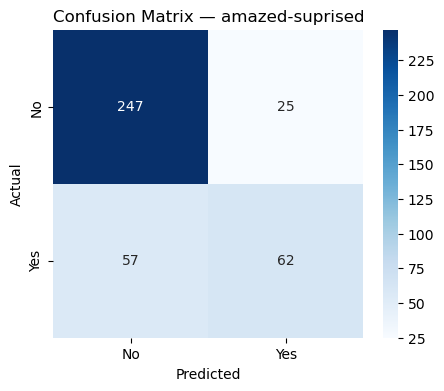

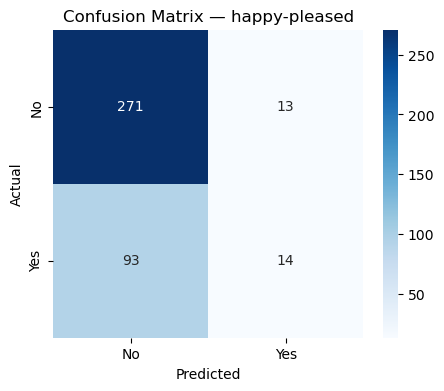

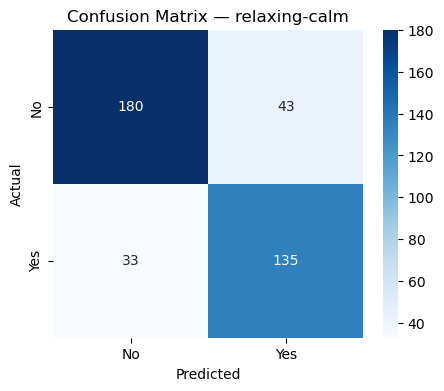

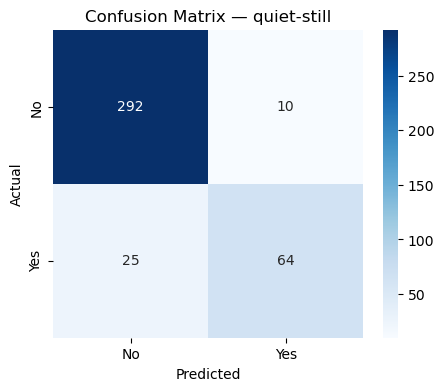

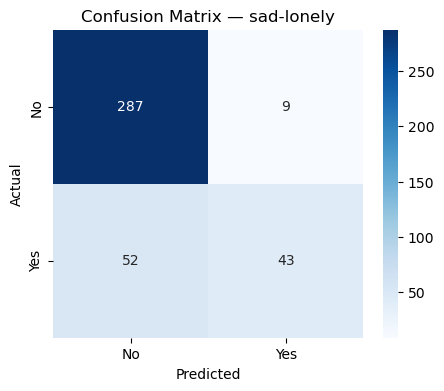

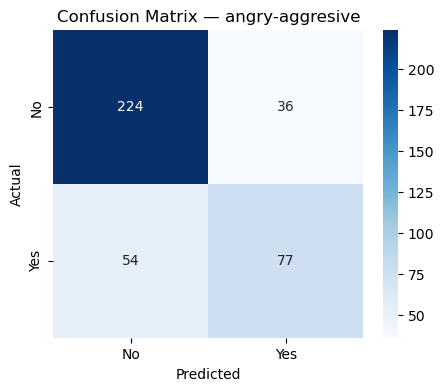

In [10]:
# 6. confusion matrices
for i, emotion in enumerate(emo_cols):

    cm = confusion_matrix(
        y_train.iloc[:, i],
        y_pred_cv[:, i]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes']
    )

    plt.title(f'Confusion Matrix — {emotion}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()

#### RF classifier chain

In [12]:
rf_chain = ClassifierChain(
    RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    order='random',
    random_state=42
)

# 2. define multilabel stratified CV
cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. define metrics
scoring = {
    'f1_macro': make_scorer(
        f1_score,
        average='macro',
        zero_division=0
    ),
    'f1_micro': make_scorer(
        f1_score,
        average='micro',
        zero_division=0
    )
}

#4. run multilabel stratified CV
cv_results = cross_validate(
    rf_chain,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 5. print metric scores
print(
    'Macro F1:',
    cv_results['test_f1_macro'].mean(),
    '+/-',
    cv_results['test_f1_macro'].std()
)

print(
    'Micro F1:',
    cv_results['test_f1_micro'].mean(),
    '+/-',
    cv_results['test_f1_micro'].std()
)

Macro F1: 0.6287550515776796 +/- 0.015796262222149204
Micro F1: 0.6760472340388417 +/- 0.01885921804543659


In [13]:
# 5. classification report
y_pred_cv = cross_val_predict(
    rf_chain,
    X_train,
    y_train,
    cv=cv,
    method='predict'
)

print(
    'Hamming Loss:',
    hamming_loss(y_train, y_pred_cv)
)

print(
    'Subset Accuracy:',
    accuracy_score(y_train, y_pred_cv)
)

report_df = pd.DataFrame(
    classification_report(
        y_train,
        y_pred_cv,
        target_names=emo_cols,
        zero_division=0,
        output_dict=True
    )
).T

report_df

Hamming Loss: 0.17902813299232737
Subset Accuracy: 0.3273657289002558


,precision,recall,f1-score,support
amazed-suprised,0.726316,0.579832,0.644860,119.0
happy-pleased,0.538462,0.130841,0.210526,107.0
relaxing-calm,0.763158,0.863095,0.810056,168.0
quiet-still,0.841463,0.775281,0.807018,89.0
sad-lonely,0.796610,0.494737,0.610390,95.0
angry-aggresive,0.696296,0.717557,0.706767,131.0
micro avg,0.746167,0.617772,0.675926,709.0
macro avg,0.727051,0.593557,0.631603,709.0
weighted avg,0.725022,0.617772,0.645631,709.0
samples avg,0.676471,0.618500,0.616709,709.0


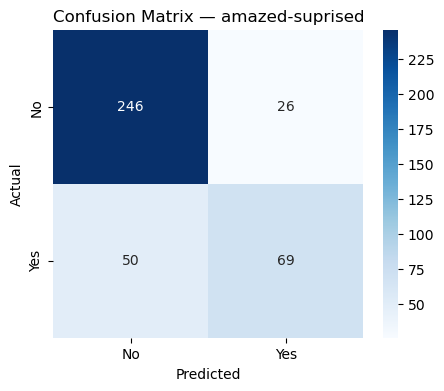

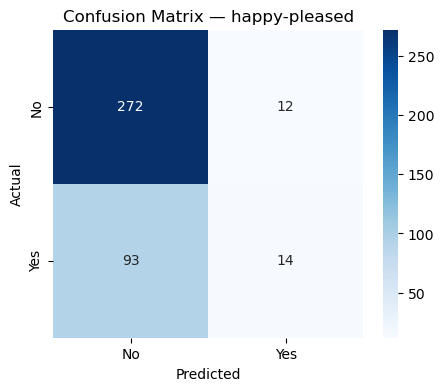

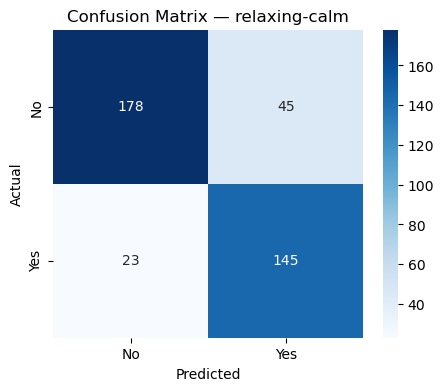

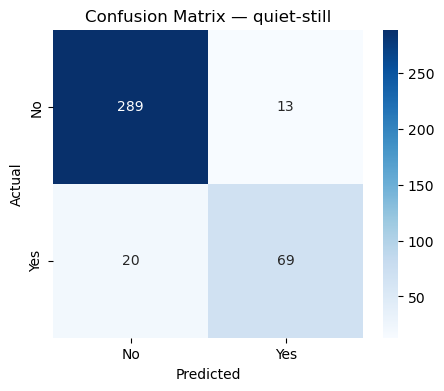

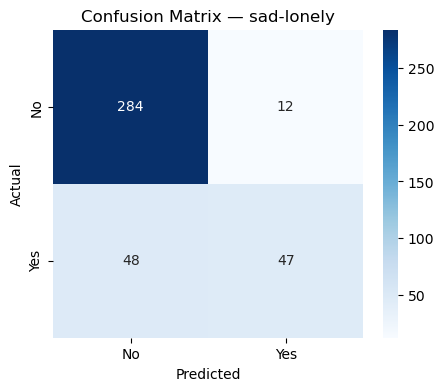

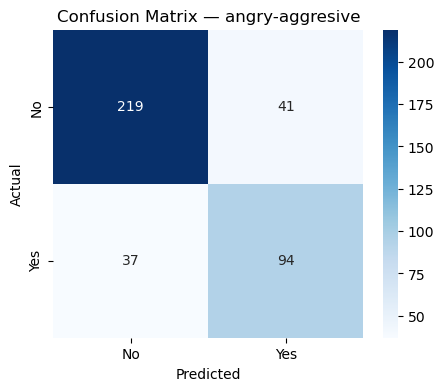

In [14]:
# 6. confusion matrices
for i, emotion in enumerate(emo_cols):

    cm = confusion_matrix(
        y_train.iloc[:, i],
        y_pred_cv[:, i]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes']
    )

    plt.title(f'Confusion Matrix — {emotion}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()

In [15]:
y_prob_cv = cross_val_predict(
    rf_chain,
    X_train,
    y_train, 
    cv=cv,
    method='predict_proba'
)

In [16]:
roc_data = []

for i, emotion in enumerate(emo_cols):
    y_true = y_train.iloc[:, i]
    y_score = y_prob_cv[:, i]

    fpr, tpr, thresholds = roc_curve(
        y_true, 
        y_score
    )

    auc = roc_auc_score(
        y_true, 
        y_score
    )

    emotion_roc = pd.DataFrame({
        'fpr': fpr, 
        'tpr': tpr,
        'threshold': thresholds,
        'emotion': emotion, 
        'auc': auc
    })

    roc_data.append(emotion_roc)

roc_df = pd.concat(
    roc_data,
    ignore_index=True
)

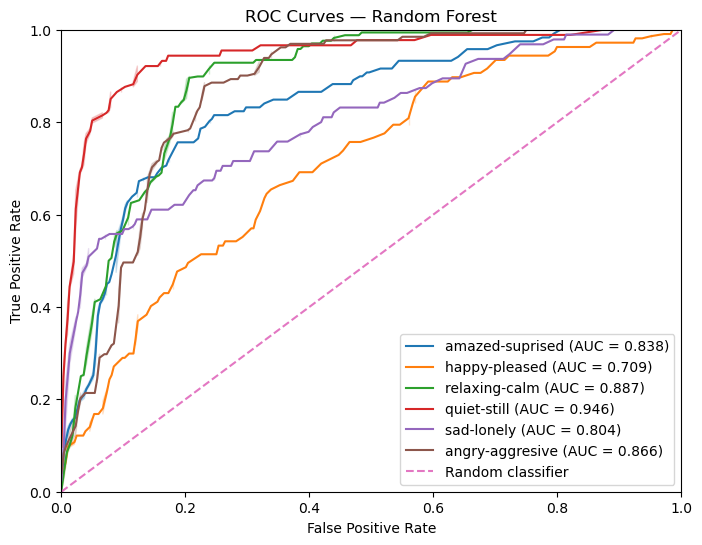

In [17]:
plt.figure(figsize=(8, 6))

for emotion in emo_cols:

    data = roc_df[
        roc_df['emotion'] == emotion
    ]

    auc_value = data['auc'].iloc[0]

    sns.lineplot(
        data=data,
        x='fpr',
        y='tpr',
        label=f'{emotion} (AUC = {auc_value:.3f})'
    )

# random-classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Random Forest')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.show()

In [18]:
#before threshold tuning, let's try changing the order of the chain

#check the order of the chain
for i, emotion in enumerate(emo_cols):
    print(i, emotion)

0 amazed-suprised
1 happy-pleased
2 relaxing-calm
3 quiet-still
4 sad-lonely
5 angry-aggresive


In [19]:
#reorder the chain and try the model again
order=[0, 1, 3, 4, 5, 2]

rf_chain_no = ClassifierChain(
    RandomForestClassifier(
        n_estimators=300, 
        class_weight='balanced',
        random_state=42, 
        n_jobs=-1
    ),
    order=order
)

# 2. define multilabel stratified CV
cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. define metrics
scoring = {
    'f1_macro': make_scorer(
        f1_score,
        average='macro',
        zero_division=0
    ),
    'f1_micro': make_scorer(
        f1_score,
        average='micro',
        zero_division=0
    )
}

#4. run multilabel stratified CV
cv_results = cross_validate(
    rf_chain_no,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 5. print metric scores
print(
    'Macro F1:',
    cv_results['test_f1_macro'].mean(),
    '+/-',
    cv_results['test_f1_macro'].std()
)

print(
    'Micro F1:',
    cv_results['test_f1_micro'].mean(),
    '+/-',
    cv_results['test_f1_micro'].std()
)

Macro F1: 0.6151973722258719 +/- 0.02143956165443113
Micro F1: 0.6569221235935843 +/- 0.01809964796934834


In [20]:
# 5. classification report
y_pred_cv = cross_val_predict(
    rf_chain_no,
    X_train,
    y_train,
    cv=cv,
    method='predict'
)

print(
    'Hamming Loss:',
    hamming_loss(y_train, y_pred_cv)
)

print(
    'Subset Accuracy:',
    accuracy_score(y_train, y_pred_cv)
)

report_df = pd.DataFrame(
    classification_report(
        y_train,
        y_pred_cv,
        target_names=emo_cols,
        zero_division=0,
        output_dict=True
    )
).T

report_df

Hamming Loss: 0.1875532821824382
Subset Accuracy: 0.29411764705882354


,precision,recall,f1-score,support
amazed-suprised,0.712644,0.521008,0.601942,119.0
happy-pleased,0.633333,0.177570,0.277372,107.0
relaxing-calm,0.751295,0.863095,0.803324,168.0
quiet-still,0.818182,0.707865,0.759036,89.0
sad-lonely,0.770492,0.494737,0.602564,95.0
angry-aggresive,0.680000,0.648855,0.664062,131.0
micro avg,0.734729,0.593794,0.656786,709.0
macro avg,0.727658,0.568855,0.618050,709.0
weighted avg,0.724801,0.593794,0.631958,709.0
samples avg,0.652600,0.589514,0.590111,709.0


In [21]:
y_prob_cv = cross_val_predict(
    rf_chain_no,
    X_train,
    y_train, 
    cv=cv,
    method='predict_proba'
)

In [22]:
roc_data = []

for i, emotion in enumerate(emo_cols):
    y_true = y_train.iloc[:, i]
    y_score = y_prob_cv[:, i]

    fpr, tpr, thresholds = roc_curve(
        y_true, 
        y_score
    )

    auc = roc_auc_score(
        y_true, 
        y_score
    )

    emotion_roc = pd.DataFrame({
        'fpr': fpr, 
        'tpr': tpr,
        'threshold': thresholds,
        'emotion': emotion, 
        'auc': auc
    })

    roc_data.append(emotion_roc)

roc_no_df = pd.concat(
    roc_data,
    ignore_index=True
)

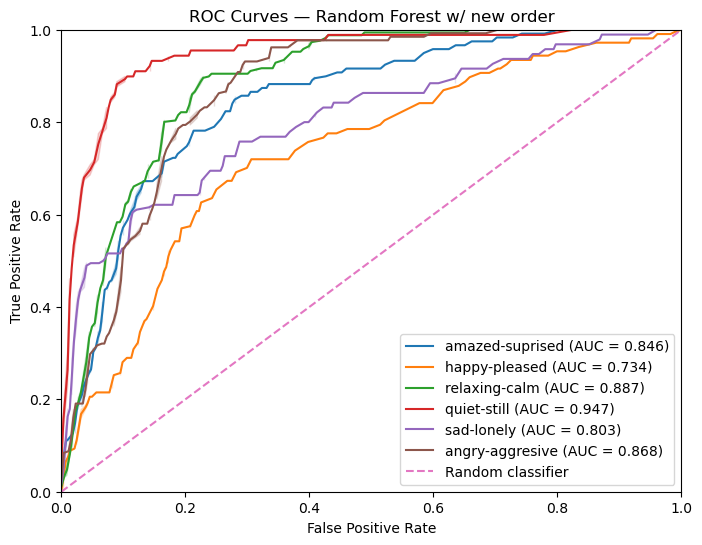

In [23]:
plt.figure(figsize=(8, 6))

for emotion in emo_cols:

    data = roc_no_df[
        roc_no_df['emotion'] == emotion
    ]

    auc_value = data['auc'].iloc[0]

    sns.lineplot(
        data=data,
        x='fpr',
        y='tpr',
        label=f'{emotion} (AUC = {auc_value:.3f})'
    )

# andom-classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Random Forest w/ new order')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.show()

Moving happy-pleased to the end of the Classifier Chain improved its ROC-AUC from 0.709 to 0.734, while the discrimination performance of the remaining emotion labels remained largely stable. This suggests that allowing happy-pleased to use information from the predictions of all preceding labels provides some additional useful signal without substantially affecting the other classes.

In [25]:
#threshold tuning
# find the position of happy-pleased
happy_idx = emo_cols.index('happy-pleased')

# extract predicted probabilities for happy-pleased
happy_prob = y_prob_cv[:, happy_idx]
target = y_train['happy-pleased']

In [26]:
#test different thresholds for happy-pleased
thresholds = np.arange(0.05, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    happy_pred = (
        happy_prob >= threshold
    ).astype(int)

    threshold_results.append({
        'threshold': threshold,
        'precision': precision_score(
            target,
            happy_pred,
            zero_division=0
        ),
        'recall': recall_score(
            target,
            happy_pred,
            zero_division=0
        ),
        'f1': f1_score(
            target,
            happy_pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,threshold,precision,recall,f1
0,0.05,0.275773,1.000000,0.432323
1,0.10,0.288889,0.971963,0.445396
2,0.15,0.326797,0.934579,0.484262
3,0.20,0.357430,0.831776,0.500000
4,0.25,0.440000,0.719626,0.546099
5,0.30,0.512000,0.598131,0.551724
6,0.35,0.516484,0.439252,0.474747
7,0.40,0.508197,0.289720,0.369048
8,0.45,0.534884,0.214953,0.306667
9,0.50,0.633333,0.177570,0.277372


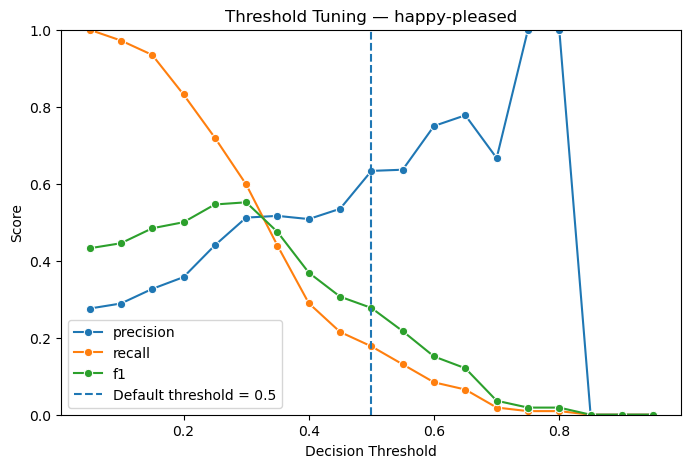

In [27]:
threshold_long = threshold_df.melt(
    id_vars='threshold',
    value_vars=['precision', 'recall', 'f1'],
    var_name='metric',
    value_name='score'
)

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=threshold_long,
    x='threshold',
    y='score',
    hue='metric',
    marker='o'
)

plt.axvline(
    0.5,
    linestyle='--',
    label='Default threshold = 0.5'
)

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title(
    'Threshold Tuning — happy-pleased'
)

plt.ylim(0, 1)
plt.legend()

plt.show()

In [28]:
# final cross-validated predictions
y_pred_tuned = (y_prob_cv >= 0.5).astype(int)

best_threshold = 0.30

y_pred_tuned[:, happy_idx] = (
    y_prob_cv[:, happy_idx] >= best_threshold
).astype(int)

In [29]:
#re-evaluate the full multilablel model
print(
    'Macro F1:',
    f1_score(
        y_train, 
        y_pred_tuned,
        average='macro',
        zero_division=0
    )
)

print(
    'Micro F1:',
    f1_score(
        y_train,
        y_pred_tuned,
        average='micro',
        zero_division=0
    )
)

print(
    'Hamming Loss:',
    hamming_loss(
        y_train,
        y_pred_tuned
    )
)

print(
    'Subset Accuracy:',
    accuracy_score(
        y_train,
        y_pred_tuned
    )
)


Macro F1: 0.6649000184009447
Micro F1: 0.67823571945047
Hamming Loss: 0.1896845694799659
Subset Accuracy: 0.309462915601023


In [30]:
# per-label report
report_tuned = pd.DataFrame(
    classification_report(
        y_train,
        y_pred_tuned,
        target_names=emo_cols,
        zero_division=0,
        output_dict=True
    )
).T

report_tuned

,precision,recall,f1-score,support
amazed-suprised,0.715909,0.529412,0.608696,119.0
happy-pleased,0.511811,0.607477,0.555556,107.0
relaxing-calm,0.751295,0.863095,0.803324,168.0
quiet-still,0.797468,0.707865,0.750000,89.0
sad-lonely,0.770492,0.494737,0.602564,95.0
angry-aggresive,0.682540,0.656489,0.669261,131.0
micro avg,0.695846,0.661495,0.678236,709.0
macro avg,0.704919,0.643179,0.664900,709.0
weighted avg,0.704878,0.661495,0.674900,709.0
samples avg,0.647272,0.657715,0.625588,709.0


In [31]:
rf_chain_no.fit(
    X_train,
    y_train
)

ClassifierChain(base_estimator=RandomForestClassifier(class_weight='balanced',
                                                      n_estimators=300,
                                                      n_jobs=-1,
                                                      random_state=42),
                order=[0, 1, 3, 4, 5, 2])

In [32]:
# 8. apply to test data
X_test = df_test.drop(columns=emo_cols)
y_test = df_test[emo_cols]

y_prob_test = rf_chain_no.predict_proba(
    X_test
)

y_pred_test_tuned = (
    y_prob_test >= 0.5
).astype(int)

y_pred_test_tuned[:, happy_idx] = (
    y_prob_test[:, happy_idx] >= best_threshold
).astype(int)

In [33]:
print(
    'Macro F1:',
    f1_score(
        y_test,
        y_pred_test_tuned,
        average='macro',
        zero_division=0
    )
)

print(
    'Micro F1:',
    f1_score(
        y_test,
        y_pred_test_tuned,
        average='micro',
        zero_division=0
    )
)

print(
    'Hamming Loss:',
    hamming_loss(
        y_test,
        y_pred_test_tuned
    )
)

print(
    'Subset Accuracy:',
    accuracy_score(
        y_test,
        y_pred_test_tuned
    )
)

Macro F1: 0.6932220285012046
Micro F1: 0.6990049751243781
Hamming Loss: 0.19966996699669967
Subset Accuracy: 0.29207920792079206


In [34]:
report_test_tuned = pd.DataFrame(
    classification_report(
        y_test,
        y_pred_test_tuned,
        target_names=emo_cols,
        zero_division=0,
        output_dict=True
    )
).T

report_test_tuned

,precision,recall,f1-score,support
amazed-suprised,0.666667,0.518519,0.583333,54.0
happy-pleased,0.470588,0.677966,0.555556,59.0
relaxing-calm,0.701754,0.833333,0.761905,96.0
quiet-still,0.803571,0.762712,0.782609,59.0
sad-lonely,0.846154,0.602740,0.704000,73.0
angry-aggresive,0.785714,0.758621,0.771930,58.0
micro avg,0.693827,0.704261,0.699005,399.0
macro avg,0.712408,0.692315,0.693222,399.0
weighted avg,0.716503,0.704261,0.701149,399.0
samples avg,0.669967,0.701320,0.654408,399.0
